# 0. Импорт вспомогательных модулей

In [15]:
import csv
import keras
from keras import layers
from keras import regularizers
import numpy as np
import matplotlib.pyplot as plt


# 1. Подготовка обучающих данных
## 1.1. Выгрузка данных для обучения из файла

In [2]:
def read_from_file(file_name):
    with open(file_name, mode="r", encoding="utf-8") as csvfile:
        reader = csv.DictReader(csvfile)
        features = reader.fieldnames
        read_data = [
            {feature: row[feature] for feature in features} for row in reader
        ]
    return features, read_data


In [3]:
train_features, read_data = read_from_file("../data/train.csv")
read_data


[{'PassengerId': '1',
  'Survived': '0',
  'Pclass': '3',
  'Name': 'Braund, Mr. Owen Harris',
  'Sex': 'male',
  'Age': '22',
  'SibSp': '1',
  'Parch': '0',
  'Ticket': 'A/5 21171',
  'Fare': '7.25',
  'Cabin': '',
  'Embarked': 'S'},
 {'PassengerId': '2',
  'Survived': '1',
  'Pclass': '1',
  'Name': 'Cumings, Mrs. John Bradley (Florence Briggs Thayer)',
  'Sex': 'female',
  'Age': '38',
  'SibSp': '1',
  'Parch': '0',
  'Ticket': 'PC 17599',
  'Fare': '71.2833',
  'Cabin': 'C85',
  'Embarked': 'C'},
 {'PassengerId': '3',
  'Survived': '1',
  'Pclass': '3',
  'Name': 'Heikkinen, Miss. Laina',
  'Sex': 'female',
  'Age': '26',
  'SibSp': '0',
  'Parch': '0',
  'Ticket': 'STON/O2. 3101282',
  'Fare': '7.925',
  'Cabin': '',
  'Embarked': 'S'},
 {'PassengerId': '4',
  'Survived': '1',
  'Pclass': '1',
  'Name': 'Futrelle, Mrs. Jacques Heath (Lily May Peel)',
  'Sex': 'female',
  'Age': '35',
  'SibSp': '1',
  'Parch': '0',
  'Ticket': '113803',
  'Fare': '53.1',
  'Cabin': 'C123',
  'E

## 1.2. Выделение данных и меток для обучения 

In [4]:
np.random.shuffle(read_data)
# features_to_use = frozenset({"Pclass", "Sex", "Age"})
features_to_use = frozenset({"Pclass", "Sex", "Age", "SibSp", "Parch"})
train_data_raw = [
    {feature: row[feature] for feature in train_features
     if feature in features_to_use} for row in read_data
]
train_labels_raw = [row["Survived"] for row in read_data]
train_data_raw


[{'Pclass': '3', 'Sex': 'female', 'Age': '22', 'SibSp': '0', 'Parch': '0'},
 {'Pclass': '3', 'Sex': 'male', 'Age': '26', 'SibSp': '0', 'Parch': '0'},
 {'Pclass': '2', 'Sex': 'female', 'Age': '22', 'SibSp': '1', 'Parch': '1'},
 {'Pclass': '3', 'Sex': 'male', 'Age': '23.5', 'SibSp': '0', 'Parch': '0'},
 {'Pclass': '3', 'Sex': 'male', 'Age': '', 'SibSp': '0', 'Parch': '0'},
 {'Pclass': '1', 'Sex': 'female', 'Age': '', 'SibSp': '1', 'Parch': '0'},
 {'Pclass': '3', 'Sex': 'male', 'Age': '33', 'SibSp': '0', 'Parch': '0'},
 {'Pclass': '3', 'Sex': 'female', 'Age': '1', 'SibSp': '1', 'Parch': '1'},
 {'Pclass': '1', 'Sex': 'male', 'Age': '', 'SibSp': '0', 'Parch': '0'},
 {'Pclass': '2', 'Sex': 'male', 'Age': '70', 'SibSp': '0', 'Parch': '0'},
 {'Pclass': '2', 'Sex': 'female', 'Age': '29', 'SibSp': '0', 'Parch': '0'},
 {'Pclass': '1', 'Sex': 'female', 'Age': '49', 'SibSp': '0', 'Parch': '0'},
 {'Pclass': '1', 'Sex': 'male', 'Age': '56', 'SibSp': '0', 'Parch': '0'},
 {'Pclass': '3', 'Sex': 'female

## 1.3. Векторизация

In [5]:
def vectorize_data(data):
    vectorized_data = [row.copy() for row in data]
    for row in vectorized_data:
        for feature in row:
            if feature == "Sex":
                if row["Sex"] == "male":
                    row["Sex"] = 1
                elif row["Sex"] == "female":
                    row["Sex"] = 0
            else:
                try:
                    row[feature] = float(row[feature])
                except ValueError:
                    row[feature] = None
    return vectorized_data


train_data_vectorized = vectorize_data(train_data_raw)
train_labels_vectorized = [float(label) for label in train_labels_raw]
train_data_vectorized


[{'Pclass': 3.0, 'Sex': 0, 'Age': 22.0, 'SibSp': 0.0, 'Parch': 0.0},
 {'Pclass': 3.0, 'Sex': 1, 'Age': 26.0, 'SibSp': 0.0, 'Parch': 0.0},
 {'Pclass': 2.0, 'Sex': 0, 'Age': 22.0, 'SibSp': 1.0, 'Parch': 1.0},
 {'Pclass': 3.0, 'Sex': 1, 'Age': 23.5, 'SibSp': 0.0, 'Parch': 0.0},
 {'Pclass': 3.0, 'Sex': 1, 'Age': None, 'SibSp': 0.0, 'Parch': 0.0},
 {'Pclass': 1.0, 'Sex': 0, 'Age': None, 'SibSp': 1.0, 'Parch': 0.0},
 {'Pclass': 3.0, 'Sex': 1, 'Age': 33.0, 'SibSp': 0.0, 'Parch': 0.0},
 {'Pclass': 3.0, 'Sex': 0, 'Age': 1.0, 'SibSp': 1.0, 'Parch': 1.0},
 {'Pclass': 1.0, 'Sex': 1, 'Age': None, 'SibSp': 0.0, 'Parch': 0.0},
 {'Pclass': 2.0, 'Sex': 1, 'Age': 70.0, 'SibSp': 0.0, 'Parch': 0.0},
 {'Pclass': 2.0, 'Sex': 0, 'Age': 29.0, 'SibSp': 0.0, 'Parch': 0.0},
 {'Pclass': 1.0, 'Sex': 0, 'Age': 49.0, 'SibSp': 0.0, 'Parch': 0.0},
 {'Pclass': 1.0, 'Sex': 1, 'Age': 56.0, 'SibSp': 0.0, 'Parch': 0.0},
 {'Pclass': 3.0, 'Sex': 0, 'Age': None, 'SibSp': 1.0, 'Parch': 0.0},
 {'Pclass': 3.0, 'Sex': 1, 'Age': 4

## 1.4. Обработка недостающих значений

In [6]:
def get_meadian_value(data, feature, group=None):
    data = [row.copy() for row in data if row[feature] != None]
    if group:
        filtered_data = [
            row for row in data if (row["Pclass"], row["Sex"]) == group
        ]
        sorted_data = sorted([row[feature] for row in filtered_data])
    else:
        sorted_data = sorted([row[feature] for row in data])
    if len(sorted_data) % 2 == 0:
        meadian_value = (
            (sorted_data[int(len(sorted_data) / 2)]
             + sorted_data[int(len(sorted_data)/2 + 1)]) / 2
        )
    else:
        meadian_value = sorted_data[int((len(sorted_data) + 1) / 2)]
    return meadian_value

def fill_data(data):
    filled_data = [row.copy() for row in data]
    for feature in filled_data[0]:
        non_empty_count = sum(
            [1 for row in filled_data if row[feature] != None]
        )
        if non_empty_count < len(filled_data):
            median_values = {
                (1., 0.): get_meadian_value(data, feature, (1., 0.)),    # Pclass: 1, Sex: 0
                (1., 1.): get_meadian_value(data, feature, (1., 1.)),    # Pclass: 1, Sex: 1
                (2., 0.): get_meadian_value(data, feature, (2., 0.)),    # Pclass: 2, Sex: 0
                (2., 1.): get_meadian_value(data, feature, (2., 1.)),    # Pclass: 2, Sex: 1
                (3., 0.): get_meadian_value(data, feature, (3., 0.)),    # Pclass: 3, Sex: 0
                (3., 1.): get_meadian_value(data, feature, (3., 1.)),    # Pclass: 3, Sex: 1
            }
            for row in filled_data:
                if not row[feature]:
                    row[feature] = median_values[(row["Pclass"], row["Sex"])]
    return filled_data


train_data_filled = fill_data(train_data_vectorized)
train_data_filled


[{'Pclass': 3.0, 'Sex': 0, 'Age': 22.0, 'SibSp': 0.0, 'Parch': 0.0},
 {'Pclass': 3.0, 'Sex': 1, 'Age': 26.0, 'SibSp': 0.0, 'Parch': 0.0},
 {'Pclass': 2.0, 'Sex': 0, 'Age': 22.0, 'SibSp': 1.0, 'Parch': 1.0},
 {'Pclass': 3.0, 'Sex': 1, 'Age': 23.5, 'SibSp': 0.0, 'Parch': 0.0},
 {'Pclass': 3.0, 'Sex': 1, 'Age': 25.0, 'SibSp': 0.0, 'Parch': 0.0},
 {'Pclass': 1.0, 'Sex': 0, 'Age': 35.0, 'SibSp': 1.0, 'Parch': 0.0},
 {'Pclass': 3.0, 'Sex': 1, 'Age': 33.0, 'SibSp': 0.0, 'Parch': 0.0},
 {'Pclass': 3.0, 'Sex': 0, 'Age': 1.0, 'SibSp': 1.0, 'Parch': 1.0},
 {'Pclass': 1.0, 'Sex': 1, 'Age': 42.0, 'SibSp': 0.0, 'Parch': 0.0},
 {'Pclass': 2.0, 'Sex': 1, 'Age': 70.0, 'SibSp': 0.0, 'Parch': 0.0},
 {'Pclass': 2.0, 'Sex': 0, 'Age': 29.0, 'SibSp': 0.0, 'Parch': 0.0},
 {'Pclass': 1.0, 'Sex': 0, 'Age': 49.0, 'SibSp': 0.0, 'Parch': 0.0},
 {'Pclass': 1.0, 'Sex': 1, 'Age': 56.0, 'SibSp': 0.0, 'Parch': 0.0},
 {'Pclass': 3.0, 'Sex': 0, 'Age': 22.0, 'SibSp': 1.0, 'Parch': 0.0},
 {'Pclass': 3.0, 'Sex': 1, 'Age': 4

## 1.5. Конструирование признаков

In [7]:
def add_features(data):
    result = [row.copy() for row in data]
    for row in result:
        if row["Age"] != None:
            if 0 <= row["Age"] < 2:
                row.update({"AgeGrp": 0.})
            elif 2 <= row["Age"] < 5:
                row.update({"AgeGrp": 1.})
            elif 5 <= row["Age"] < 15:
                row.update({"AgeGrp": 2.})
            elif 15 <= row["Age"] < 25:
                row.update({"AgeGrp": 3.})
            elif 25 <= row["Age"] < 40:
                row.update({"AgeGrp": 4.})
            elif 40 <= row["Age"] < 60:
                row.update({"AgeGrp": 5.})
            elif 60 <= row["Age"] < 70:
                row.update({"AgeGrp": 6.})
            elif 70 <= row["Age"]:
                row.update({"AgeGrp": 7.})
        else:
            row.update({"AgeGrp": 8.})
        del row["Age"]
        # family_size = row["SibSp"] + row["Parch"]
        # if family_size > 0:
        #     row.update({"/wFamily": 1.})
        # else:
        #     row.update({"/wFamily": 0.})
        # del row["SibSp"]
        # del row["Parch"]
    return result


# train_data_upgraded = add_features(train_data_vectorized)
train_data_upgraded = add_features(train_data_filled)
train_data_upgraded


[{'Pclass': 3.0, 'Sex': 0, 'SibSp': 0.0, 'Parch': 0.0, 'AgeGrp': 3.0},
 {'Pclass': 3.0, 'Sex': 1, 'SibSp': 0.0, 'Parch': 0.0, 'AgeGrp': 4.0},
 {'Pclass': 2.0, 'Sex': 0, 'SibSp': 1.0, 'Parch': 1.0, 'AgeGrp': 3.0},
 {'Pclass': 3.0, 'Sex': 1, 'SibSp': 0.0, 'Parch': 0.0, 'AgeGrp': 3.0},
 {'Pclass': 3.0, 'Sex': 1, 'SibSp': 0.0, 'Parch': 0.0, 'AgeGrp': 4.0},
 {'Pclass': 1.0, 'Sex': 0, 'SibSp': 1.0, 'Parch': 0.0, 'AgeGrp': 4.0},
 {'Pclass': 3.0, 'Sex': 1, 'SibSp': 0.0, 'Parch': 0.0, 'AgeGrp': 4.0},
 {'Pclass': 3.0, 'Sex': 0, 'SibSp': 1.0, 'Parch': 1.0, 'AgeGrp': 0.0},
 {'Pclass': 1.0, 'Sex': 1, 'SibSp': 0.0, 'Parch': 0.0, 'AgeGrp': 5.0},
 {'Pclass': 2.0, 'Sex': 1, 'SibSp': 0.0, 'Parch': 0.0, 'AgeGrp': 7.0},
 {'Pclass': 2.0, 'Sex': 0, 'SibSp': 0.0, 'Parch': 0.0, 'AgeGrp': 4.0},
 {'Pclass': 1.0, 'Sex': 0, 'SibSp': 0.0, 'Parch': 0.0, 'AgeGrp': 5.0},
 {'Pclass': 1.0, 'Sex': 1, 'SibSp': 0.0, 'Parch': 0.0, 'AgeGrp': 5.0},
 {'Pclass': 3.0, 'Sex': 0, 'SibSp': 1.0, 'Parch': 0.0, 'AgeGrp': 3.0},
 {'Pcl

## 1.6. Нормализация значений

In [8]:
def normalize_data(data):
    normalized_data = [row.copy() for row in data]
    # discrete_features = frozenset({"Pclass", "Sex"})
    # continuous_features = frozenset({"Age", "Parch", "SibSp"})
    discrete_features = frozenset({"AgeGrp", "Pclass", "Sex"})
    continuous_features = frozenset({"Parch", "SibSp"})
    for feature in discrete_features:
        # max_val = max([row[feature] for row in normalized_data])
        # for row in normalized_data:
        #     row[feature] /= max_val
        if feature == "AgeGrp":
            for row in normalized_data:
                row[feature] /= 7
        elif feature == "Pclass":
            for row in normalized_data:
                row[feature] /= 3
    for feature in continuous_features:
        mean_val = (
            sum([row[feature] for row in normalized_data if row[feature]])
            / len(normalized_data)
        )
        std_dev = np.sqrt(
            sum([(row[feature] - mean_val)**2 for row in normalized_data
                 if row[feature]]) / len(normalized_data)
        )
        for row in normalized_data:
            row[feature] -= mean_val
            row[feature] /= std_dev
    return normalized_data
    

In [9]:
# # train_data_normalized = normalize_data(train_data_filled)
train_data_normalized = normalize_data(train_data_upgraded)
train_data_normalized

[{'Pclass': 1.0,
  'Sex': 0,
  'SibSp': -0.5158304584547138,
  'Parch': -0.5201531893312331,
  'AgeGrp': 0.42857142857142855},
 {'Pclass': 1.0,
  'Sex': 1,
  'SibSp': -0.5158304584547138,
  'Parch': -0.5201531893312331,
  'AgeGrp': 0.5714285714285714},
 {'Pclass': 0.6666666666666666,
  'Sex': 0,
  'SibSp': 0.4704462335692132,
  'Parch': 0.8429541391809101,
  'AgeGrp': 0.42857142857142855},
 {'Pclass': 1.0,
  'Sex': 1,
  'SibSp': -0.5158304584547138,
  'Parch': -0.5201531893312331,
  'AgeGrp': 0.42857142857142855},
 {'Pclass': 1.0,
  'Sex': 1,
  'SibSp': -0.5158304584547138,
  'Parch': -0.5201531893312331,
  'AgeGrp': 0.5714285714285714},
 {'Pclass': 0.3333333333333333,
  'Sex': 0,
  'SibSp': 0.4704462335692132,
  'Parch': -0.5201531893312331,
  'AgeGrp': 0.5714285714285714},
 {'Pclass': 1.0,
  'Sex': 1,
  'SibSp': -0.5158304584547138,
  'Parch': -0.5201531893312331,
  'AgeGrp': 0.5714285714285714},
 {'Pclass': 1.0,
  'Sex': 0,
  'SibSp': 0.4704462335692132,
  'Parch': 0.842954139180910

## 1.7. Формирование массива данных для обучения

In [10]:
def extract_data(data):
    extracted_data = np.array(
        [[row[feature] for feature in row] for row in data]
    )
    return extracted_data


train_data = extract_data(train_data_normalized)
train_labels = np.array(train_labels_vectorized)
train_data


array([[ 1.        ,  0.        , -0.51583046, -0.52015319,  0.42857143],
       [ 1.        ,  1.        , -0.51583046, -0.52015319,  0.57142857],
       [ 0.66666667,  0.        ,  0.47044623,  0.84295414,  0.42857143],
       ...,
       [ 0.33333333,  1.        , -0.51583046, -0.52015319,  1.        ],
       [ 1.        ,  1.        , -0.51583046, -0.52015319,  0.57142857],
       [ 0.66666667,  1.        , -0.51583046, -0.52015319,  0.42857143]])

# 2. Обучение модели
## 2.1. Валидация

In [19]:
def build_model():
    num_of_neurons = 2048
    num_of_layers = 10
    layers_list = []
    for _ in range(num_of_layers):
        layers_list.append(
            layers.Dense(num_of_neurons,
                         kernel_regularizer=regularizers.L2(1e-3),
                         activation="relu")
        )
        # layers_list.append(layers.Dropout(0.5))
    layers_list.append(layers.Dense(1, activation="sigmoid"))
    model = keras.Sequential(layers_list)
    model.compile(optimizer=keras.optimizers.RMSprop(learning_rate=1e-5),
                  loss="binary_crossentropy",
                  metrics=["accuracy"])
    return model


k = 5
num_of_val_samples = len(train_data) // k
num_of_epochs = 500
validation_losses = []
validation_accuracies = []
batch_size = 128
for i in range(k):
    print(f"Processing fold #{i+1} out of {k}...")
    val_data = train_data[i*num_of_val_samples:(i+1)*num_of_val_samples]
    val_labels = train_labels[i*num_of_val_samples:(i+1)*num_of_val_samples]
    train_data_partial = np.concatenate(
        [
            train_data[:i*num_of_val_samples],
            train_data[(i+1)*num_of_val_samples:]
        ]
    )
    train_labels_partial = np.concatenate(
        [
            train_labels[:i*num_of_val_samples],
            train_labels[(i+1)*num_of_val_samples:]
        ]
    )
    model = build_model()
    history = model.fit(train_data_partial,
                        train_labels_partial,
                        epochs=num_of_epochs,
                        batch_size=batch_size,
                        validation_data=(val_data, val_labels),
                        verbose=0)
    validation_loss_history = history.history["val_loss"]
    validation_losses.append(validation_loss_history)
    validation_accuracy_history = history.history["val_accuracy"]
    validation_accuracies.append(validation_accuracy_history)
print("Done.")


Processing fold #1 out of 5...
Processing fold #2 out of 5...
Processing fold #3 out of 5...
Processing fold #4 out of 5...
Processing fold #5 out of 5...
Done.


## 2.2. Визуализация результатов валидации

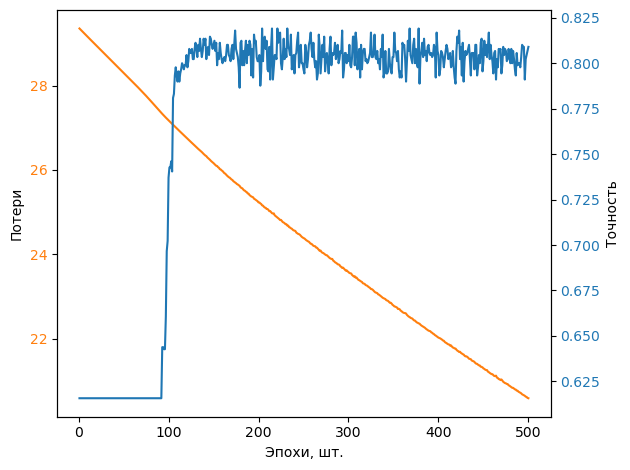

In [21]:
validation_losses_average = [
    np.mean([l[i] for l in validation_losses])
    for i in range(num_of_epochs)
]
validation_accuracies_average = [
    np.mean([l[i] for l in validation_accuracies])
    for i in range(num_of_epochs)
]
fig, ax1 = plt.subplots()
color = "tab:orange"
ax1.plot(range(
    1, num_of_epochs+1), validation_losses_average, color=color
)
ax1.set_xlabel("Эпохи, шт.")
ax1.set_ylabel("Потери")
ax1.tick_params(axis="y", labelcolor=color)
ax2 = ax1.twinx()
color = "tab:blue"
ax2.plot(
    range(1, num_of_epochs+1), validation_accuracies_average, color=color
)
ax2.set_ylabel("Точность")
ax2.tick_params(axis="y", labelcolor=color)
fig.tight_layout()
plt.show()


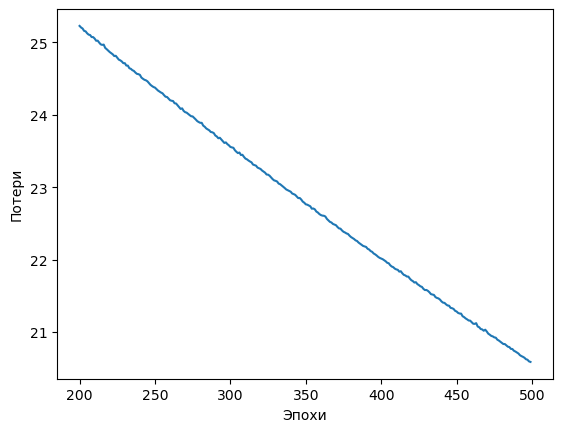

In [23]:
validation_losses_truncated =validation_losses_average[200:500]
plt.plot(range(200, 500), validation_losses_truncated)
plt.xlabel("Эпохи")
plt.ylabel("Потери")
plt.show()


## 2.3. Определение эпохи переобучения

In [25]:
oferfitting_epoch = validation_losses_average.index(
    min(validation_losses_average)
)
oferfitting_epoch


499

In [26]:
validation_accuracies_average[oferfitting_epoch], min(validation_losses_average)

(0.8089887499809265, 20.58794174194336)

## 2.4. Обучение новой модели

In [15]:
new_model = build_model()
print("Fitting new model...")
new_model.fit(train_data,
              train_labels,
              epochs=oferfitting_epoch,
              batch_size=256,
              verbose=0)
print("New model has been fitted.")


Fitting new model...
New model has been fitted.


# 3. Подготовка данных для предсказаний
## 3.1. Выгрузка данных для предсказаний из файла

In [16]:
test_features, read_data = read_from_file("../data/test.csv")
read_data


[{'PassengerId': '892',
  'Pclass': '3',
  'Name': 'Kelly, Mr. James',
  'Sex': 'male',
  'Age': '34.5',
  'SibSp': '0',
  'Parch': '0',
  'Ticket': '330911',
  'Fare': '7.8292',
  'Cabin': '',
  'Embarked': 'Q'},
 {'PassengerId': '893',
  'Pclass': '3',
  'Name': 'Wilkes, Mrs. James (Ellen Needs)',
  'Sex': 'female',
  'Age': '47',
  'SibSp': '1',
  'Parch': '0',
  'Ticket': '363272',
  'Fare': '7',
  'Cabin': '',
  'Embarked': 'S'},
 {'PassengerId': '894',
  'Pclass': '2',
  'Name': 'Myles, Mr. Thomas Francis',
  'Sex': 'male',
  'Age': '62',
  'SibSp': '0',
  'Parch': '0',
  'Ticket': '240276',
  'Fare': '9.6875',
  'Cabin': '',
  'Embarked': 'Q'},
 {'PassengerId': '895',
  'Pclass': '3',
  'Name': 'Wirz, Mr. Albert',
  'Sex': 'male',
  'Age': '27',
  'SibSp': '0',
  'Parch': '0',
  'Ticket': '315154',
  'Fare': '8.6625',
  'Cabin': '',
  'Embarked': 'S'},
 {'PassengerId': '896',
  'Pclass': '3',
  'Name': 'Hirvonen, Mrs. Alexander (Helga E Lindqvist)',
  'Sex': 'female',
  'Age': '

## 3.2. Выделение данных для предсказаний

In [17]:
test_data_raw = [
    {feature: row[feature] for feature in test_features
     if feature in features_to_use} for row in read_data
]
test_data_raw


[{'Pclass': '3', 'Sex': 'male', 'Age': '34.5', 'SibSp': '0', 'Parch': '0'},
 {'Pclass': '3', 'Sex': 'female', 'Age': '47', 'SibSp': '1', 'Parch': '0'},
 {'Pclass': '2', 'Sex': 'male', 'Age': '62', 'SibSp': '0', 'Parch': '0'},
 {'Pclass': '3', 'Sex': 'male', 'Age': '27', 'SibSp': '0', 'Parch': '0'},
 {'Pclass': '3', 'Sex': 'female', 'Age': '22', 'SibSp': '1', 'Parch': '1'},
 {'Pclass': '3', 'Sex': 'male', 'Age': '14', 'SibSp': '0', 'Parch': '0'},
 {'Pclass': '3', 'Sex': 'female', 'Age': '30', 'SibSp': '0', 'Parch': '0'},
 {'Pclass': '2', 'Sex': 'male', 'Age': '26', 'SibSp': '1', 'Parch': '1'},
 {'Pclass': '3', 'Sex': 'female', 'Age': '18', 'SibSp': '0', 'Parch': '0'},
 {'Pclass': '3', 'Sex': 'male', 'Age': '21', 'SibSp': '2', 'Parch': '0'},
 {'Pclass': '3', 'Sex': 'male', 'Age': '', 'SibSp': '0', 'Parch': '0'},
 {'Pclass': '1', 'Sex': 'male', 'Age': '46', 'SibSp': '0', 'Parch': '0'},
 {'Pclass': '1', 'Sex': 'female', 'Age': '23', 'SibSp': '1', 'Parch': '0'},
 {'Pclass': '2', 'Sex': 'mal

## 3.3. Векторизация

In [18]:
test_data_vectorized = vectorize_data(test_data_raw)
test_data_vectorized


[{'Pclass': 3.0, 'Sex': 1, 'Age': 34.5, 'SibSp': 0.0, 'Parch': 0.0},
 {'Pclass': 3.0, 'Sex': 0, 'Age': 47.0, 'SibSp': 1.0, 'Parch': 0.0},
 {'Pclass': 2.0, 'Sex': 1, 'Age': 62.0, 'SibSp': 0.0, 'Parch': 0.0},
 {'Pclass': 3.0, 'Sex': 1, 'Age': 27.0, 'SibSp': 0.0, 'Parch': 0.0},
 {'Pclass': 3.0, 'Sex': 0, 'Age': 22.0, 'SibSp': 1.0, 'Parch': 1.0},
 {'Pclass': 3.0, 'Sex': 1, 'Age': 14.0, 'SibSp': 0.0, 'Parch': 0.0},
 {'Pclass': 3.0, 'Sex': 0, 'Age': 30.0, 'SibSp': 0.0, 'Parch': 0.0},
 {'Pclass': 2.0, 'Sex': 1, 'Age': 26.0, 'SibSp': 1.0, 'Parch': 1.0},
 {'Pclass': 3.0, 'Sex': 0, 'Age': 18.0, 'SibSp': 0.0, 'Parch': 0.0},
 {'Pclass': 3.0, 'Sex': 1, 'Age': 21.0, 'SibSp': 2.0, 'Parch': 0.0},
 {'Pclass': 3.0, 'Sex': 1, 'Age': None, 'SibSp': 0.0, 'Parch': 0.0},
 {'Pclass': 1.0, 'Sex': 1, 'Age': 46.0, 'SibSp': 0.0, 'Parch': 0.0},
 {'Pclass': 1.0, 'Sex': 0, 'Age': 23.0, 'SibSp': 1.0, 'Parch': 0.0},
 {'Pclass': 2.0, 'Sex': 1, 'Age': 63.0, 'SibSp': 1.0, 'Parch': 0.0},
 {'Pclass': 1.0, 'Sex': 0, 'Age': 

## 3.4. Обработка недостающих значений

In [19]:
test_data_filled = fill_data(test_data_vectorized)
test_data_filled


[{'Pclass': 3.0, 'Sex': 1, 'Age': 34.5, 'SibSp': 0.0, 'Parch': 0.0},
 {'Pclass': 3.0, 'Sex': 0, 'Age': 47.0, 'SibSp': 1.0, 'Parch': 0.0},
 {'Pclass': 2.0, 'Sex': 1, 'Age': 62.0, 'SibSp': 0.0, 'Parch': 0.0},
 {'Pclass': 3.0, 'Sex': 1, 'Age': 27.0, 'SibSp': 0.0, 'Parch': 0.0},
 {'Pclass': 3.0, 'Sex': 0, 'Age': 22.0, 'SibSp': 1.0, 'Parch': 1.0},
 {'Pclass': 3.0, 'Sex': 1, 'Age': 14.0, 'SibSp': 0.0, 'Parch': 0.0},
 {'Pclass': 3.0, 'Sex': 0, 'Age': 30.0, 'SibSp': 0.0, 'Parch': 0.0},
 {'Pclass': 2.0, 'Sex': 1, 'Age': 26.0, 'SibSp': 1.0, 'Parch': 1.0},
 {'Pclass': 3.0, 'Sex': 0, 'Age': 18.0, 'SibSp': 0.0, 'Parch': 0.0},
 {'Pclass': 3.0, 'Sex': 1, 'Age': 21.0, 'SibSp': 2.0, 'Parch': 0.0},
 {'Pclass': 3.0, 'Sex': 1, 'Age': 24.0, 'SibSp': 0.0, 'Parch': 0.0},
 {'Pclass': 1.0, 'Sex': 1, 'Age': 46.0, 'SibSp': 0.0, 'Parch': 0.0},
 {'Pclass': 1.0, 'Sex': 0, 'Age': 23.0, 'SibSp': 1.0, 'Parch': 0.0},
 {'Pclass': 2.0, 'Sex': 1, 'Age': 63.0, 'SibSp': 1.0, 'Parch': 0.0},
 {'Pclass': 1.0, 'Sex': 0, 'Age': 

## 3.5. Конструирование признаков

In [20]:
test_data_upgraded = add_features(test_data_filled)
test_data_upgraded


[{'Pclass': 3.0, 'Sex': 1, 'SibSp': 0.0, 'Parch': 0.0, 'AgeGrp': 4.0},
 {'Pclass': 3.0, 'Sex': 0, 'SibSp': 1.0, 'Parch': 0.0, 'AgeGrp': 5.0},
 {'Pclass': 2.0, 'Sex': 1, 'SibSp': 0.0, 'Parch': 0.0, 'AgeGrp': 6.0},
 {'Pclass': 3.0, 'Sex': 1, 'SibSp': 0.0, 'Parch': 0.0, 'AgeGrp': 4.0},
 {'Pclass': 3.0, 'Sex': 0, 'SibSp': 1.0, 'Parch': 1.0, 'AgeGrp': 3.0},
 {'Pclass': 3.0, 'Sex': 1, 'SibSp': 0.0, 'Parch': 0.0, 'AgeGrp': 2.0},
 {'Pclass': 3.0, 'Sex': 0, 'SibSp': 0.0, 'Parch': 0.0, 'AgeGrp': 4.0},
 {'Pclass': 2.0, 'Sex': 1, 'SibSp': 1.0, 'Parch': 1.0, 'AgeGrp': 4.0},
 {'Pclass': 3.0, 'Sex': 0, 'SibSp': 0.0, 'Parch': 0.0, 'AgeGrp': 3.0},
 {'Pclass': 3.0, 'Sex': 1, 'SibSp': 2.0, 'Parch': 0.0, 'AgeGrp': 3.0},
 {'Pclass': 3.0, 'Sex': 1, 'SibSp': 0.0, 'Parch': 0.0, 'AgeGrp': 3.0},
 {'Pclass': 1.0, 'Sex': 1, 'SibSp': 0.0, 'Parch': 0.0, 'AgeGrp': 5.0},
 {'Pclass': 1.0, 'Sex': 0, 'SibSp': 1.0, 'Parch': 0.0, 'AgeGrp': 3.0},
 {'Pclass': 2.0, 'Sex': 1, 'SibSp': 1.0, 'Parch': 0.0, 'AgeGrp': 6.0},
 {'Pcl

## 3.6. Нормализация значений

In [35]:
test_data_normalized = normalize_data(test_data_upgraded)
test_data_normalized


[{'Pclass': 1.0,
  'Sex': 1,
  'SibSp': -0.5478765534939781,
  'Parch': -0.4276806768041529,
  'AgeGrp': 0.5714285714285714},
 {'Pclass': 1.0,
  'Sex': 0,
  'SibSp': 0.6767886837278553,
  'Parch': -0.4276806768041529,
  'AgeGrp': 0.7142857142857143},
 {'Pclass': 0.6666666666666666,
  'Sex': 1,
  'SibSp': -0.5478765534939781,
  'Parch': -0.4276806768041529,
  'AgeGrp': 0.8571428571428571},
 {'Pclass': 1.0,
  'Sex': 1,
  'SibSp': -0.5478765534939781,
  'Parch': -0.4276806768041529,
  'AgeGrp': 0.5714285714285714},
 {'Pclass': 1.0,
  'Sex': 0,
  'SibSp': 0.6767886837278553,
  'Parch': 0.6623834872454563,
  'AgeGrp': 0.42857142857142855},
 {'Pclass': 1.0,
  'Sex': 1,
  'SibSp': -0.5478765534939781,
  'Parch': -0.4276806768041529,
  'AgeGrp': 0.2857142857142857},
 {'Pclass': 1.0,
  'Sex': 0,
  'SibSp': -0.5478765534939781,
  'Parch': -0.4276806768041529,
  'AgeGrp': 0.5714285714285714},
 {'Pclass': 0.6666666666666666,
  'Sex': 1,
  'SibSp': 0.6767886837278553,
  'Parch': 0.6623834872454563,

## 3.7. Формирование массива данных для предсказаний

In [31]:
test_data = extract_data(test_data_normalized)
test_data


array([[ 1.        ,  1.        , -0.54787655, -0.42768068,  0.5       ],
       [ 1.        ,  0.        ,  0.67678868, -0.42768068,  0.625     ],
       [ 0.66666667,  1.        , -0.54787655, -0.42768068,  0.75      ],
       ...,
       [ 1.        ,  1.        , -0.54787655, -0.42768068,  0.5       ],
       [ 1.        ,  1.        , -0.54787655, -0.42768068,  0.375     ],
       [ 1.        ,  1.        ,  0.67678868,  0.66238349,  0.375     ]])

# 4. Формирование предсказаний
## 4.1. Получение вероятности выживания

In [23]:
predictions_raw = new_model.predict(test_data, verbose=0)
predictions_raw


array([[0.12838365],
       [0.19968873],
       [0.13362241],
       [0.12838365],
       [0.6404509 ],
       [0.15496024],
       [0.5160396 ],
       [0.1878914 ],
       [0.6998278 ],
       [0.09724613],
       [0.13596287],
       [0.21582898],
       [0.9771195 ],
       [0.14408894],
       [0.97649515],
       [0.9327052 ],
       [0.16990364],
       [0.13596287],
       [0.35100323],
       [0.24617061],
       [0.37749127],
       [0.7239837 ],
       [0.97915125],
       [0.57882684],
       [0.96671236],
       [0.11768897],
       [0.9762325 ],
       [0.13596287],
       [0.21582898],
       [0.09724613],
       [0.15808941],
       [0.1457117 ],
       [0.418054  ],
       [0.64166665],
       [0.6069295 ],
       [0.13596287],
       [0.6998278 ],
       [0.6998278 ],
       [0.12838365],
       [0.13596287],
       [0.14352745],
       [0.21582898],
       [0.11937574],
       [0.9237832 ],
       [0.97649515],
       [0.12838365],
       [0.21582898],
       [0.135

## 4.2. Округление значений до целого

In [24]:
predictions = [
    int(round(prediction[0], 0)) for prediction in predictions_raw
]
predictions


[0,
 0,
 0,
 0,
 1,
 0,
 1,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 1,
 1,
 0,
 0,
 0,
 0,
 0,
 1,
 1,
 1,
 1,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 1,
 0,
 1,
 1,
 0,
 0,
 0,
 0,
 0,
 1,
 1,
 0,
 0,
 0,
 1,
 1,
 0,
 0,
 1,
 1,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 1,
 1,
 0,
 1,
 1,
 1,
 0,
 1,
 1,
 1,
 1,
 0,
 1,
 0,
 1,
 1,
 0,
 0,
 0,
 0,
 0,
 1,
 1,
 1,
 1,
 1,
 0,
 1,
 0,
 1,
 0,
 1,
 0,
 1,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 1,
 1,
 1,
 0,
 0,
 1,
 1,
 1,
 1,
 0,
 1,
 0,
 0,
 1,
 0,
 1,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 1,
 0,
 0,
 1,
 1,
 0,
 1,
 1,
 1,
 1,
 0,
 0,
 0,
 0,
 0,
 1,
 1,
 0,
 0,
 0,
 0,
 0,
 1,
 1,
 0,
 1,
 1,
 0,
 1,
 1,
 0,
 1,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 1,
 0,
 1,
 1,
 0,
 1,
 1,
 1,
 0,
 1,
 0,
 0,
 1,
 0,
 1,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 1,
 0,
 1,
 0,
 1,
 0,
 1,
 0,
 1,
 1,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 0,
 1,
 0,
 0,
 0,
 1,
 1,
 1,
 1,
 0,
 0,
 0,
 0,
 1,
 0,
 1,
 1,


## 4.3. Запись результатов в файл

In [25]:
with open("../data/submission.csv", mode="w", encoding="utf-8", newline='') as csvfile:
    writer = csv.DictWriter(csvfile, fieldnames=["PassengerId", "Survived"])
    writer.writeheader()
    for i, prediction in enumerate(predictions):
        writer.writerow(
            {
                "PassengerId": read_data[i]["PassengerId"],
                "Survived": prediction
            }
        )
    print("File has been written.")


File has been written.
